### Checking different columns in files

In [ ]:
#pyspark jupyter notebook matplotlib pandas pyarrow

In [1]:
import os
import sys

os.environ["PYSPARK_PYTHON"] = sys.executable  # Usa el Python del entorno actual
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"  # Spark 4.2 requiere un Java compatible
os.environ["PATH"] = os.path.join(os.environ["JAVA_HOME"], "bin") + os.pathsep + os.environ["PATH"]

In [2]:
from pyspark.sql import SparkSession
spark = SparkSession.builder.master("local[*]") \
    .config("spark.driver.memory", "8g") \
    .config("spark.executor.memory", "8g") \
    .config("spark.python.worker.memory", "2g") \
    .config("spark.python.worker.reuse", "true") \
    .config("spark.python.profile", "true") \
    .config("spark.python.connect.timeout", "60s") \
    .getOrCreate()

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/12 17:11:44 WARN Utils: Your hostname, DESKTOP-EKA7S1C, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/10/12 17:11:44 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/diego/repos/data-processing/.venv/lib/python3.12/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/10/12 17:11:45 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/12 17:11:46 WARN Utils: Service

In [3]:
from pyspark.sql import SparkSession
spark = SparkSession.builder.getOrCreate()

In [4]:
import pyspark.pandas as ps
import pandas as pd
import re
import os
from pyspark.sql import Row
from pyspark.sql.types import *
from IPython.display import display, HTML
from pyspark.sql.functions import col, split, lit, count, when, trim, startswith, lower, to_date, datediff, avg, min, max, stddev, mean, kurtosis, skewness


/home/diego/repos/data-processing/.venv/lib/python3.12/site-packages/pyspark/pandas/__init__.py:33: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


In [5]:
!java -version

openjdk version "17.0.20.1" 2026-08-18
OpenJDK Runtime Environment (build 17.0.20.1+1-1-24.04-Ubuntu)
OpenJDK 64-Bit Server VM (build 17.0.20.1+1-1-24.04-Ubuntu, mixed mode, sharing)


In [6]:
spark.conf.set("spark.sql.repl.eagerEval.enabled", True) # pretty print dataframe
spark.conf.set("spark.sql.repl.eagerEval.truncate", 50) # pretty print dataframe
spark.sparkContext.setLogLevel("ERROR") # remove warnings
spark.conf.set('spark.rapids.sql.enabled','true')
spark.conf.set('spark.rapids.sql.incompatibleOps.enabled', 'true')
spark.conf.set('spark.rapids.sql.format.csv.read.enabled', 'true')
spark.conf.set('spark.rapids.sql.format.csv.enabled', 'true')

        

In [10]:
file_path = "../data/raw/sivigila/csv"
dir_list = sorted(os.listdir(file_path))

columns_by_file = {}

for file in dir_list:
    if file.lower().endswith(".csv"):
        with open(os.path.join(file_path, file), encoding="utf-8-sig") as f:
            columns = set(f.readline().strip().split(";"))
            columns_by_file[file] = columns

# Columnas presentes en TODOS los archivos
common_columns = set.intersection(*columns_by_file.values())

# Columnas presentes en al menos un archivo
all_columns = set.union(*columns_by_file.values())

# Columnas que no están en todos los archivos
different_columns = all_columns - common_columns

print("Columnas diferentes:")
print(different_columns)

Columnas diferentes:
set()


### Opening files

In [11]:
files = sorted([
    f for f in os.listdir(file_path)
    if f.endswith(".csv")
])

df = None

for file in files:
    year = re.search(r"\d{4}", file).group()
    filename = f"Datos_{year}"

    df_tmp = (
        spark.read
        .option("delimiter", ",")
        .option("header", True)
        .csv(os.path.join(file_path, file))
        .withColumn("filename", lit(filename))
    )

    df = df_tmp if df is None else df.unionByName(df_tmp)

In [9]:
df.count()

1257304

### Columns

In [17]:
print('Columns overview')
df_columns = pd.DataFrame(df.dtypes, columns = ['Column Name','Data type'])
display(HTML(df_columns.to_html()))

Columns overview


,Column Name,Data type
0,CONSECUTIVE,string
1,COD_EVE,string
2,FEC_NOT,string
3,SEMANA,string
4,ANO,string
5,COD_PRE,string
6,COD_SUB,string
7,EDAD,string
8,UNI_MED,string
9,SEXO,string


In [11]:
list_col_names = df_columns['Column Name'].to_list()
print(len(list_col_names))
list_col_names

70


['CONSECUTIVE',
 'COD_EVE',
 'FEC_NOT',
 'SEMANA',
 'ANO',
 'COD_PRE',
 'COD_SUB',
 'EDAD',
 'UNI_MED',
 'SEXO',
 'COD_PAIS_O',
 'COD_DPTO_O',
 'COD_MUN_O',
 'AREA',
 'OCUPACION',
 'TIP_SS',
 'COD_ASE',
 'PER_ETN',
 'GRU_POB',
 'nom_grupo',
 'estrato',
 'GP_DISCAPA',
 'GP_DESPLAZ',
 'GP_MIGRANT',
 'GP_CARCELA',
 'GP_GESTAN',
 'sem_ges',
 'GP_INDIGEN',
 'GP_POBICFB',
 'GP_MAD_COM',
 'GP_DESMOVI',
 'GP_PSIQUIA',
 'GP_VIC_VIO',
 'GP_OTROS',
 'fuente',
 'COD_PAIS_R',
 'COD_DPTO_R',
 'COD_MUN_R',
 'COD_DPTO_N',
 'COD_MUN_N',
 'FEC_CON',
 'INI_SIN',
 'TIP_CAS',
 'PAC_HOS',
 'FEC_HOS',
 'CON_FIN',
 'FEC_DEF',
 'AJUSTE',
 'FECHA_NTO',
 'CBMTE',
 'FEC_ARC_XL',
 'FEC_AJU',
 'FM_FUERZA',
 'FM_UNIDAD',
 'FM_GRADO',
 'confirmados',
 'va_sispro',
 'Estado_final_de_caso',
 'nom_est_f_caso',
 'Nombre_upgd',
 'Pais_ocurrencia',
 'Nombre_evento',
 'Departamento_ocurrencia',
 'Municipio_ocurrencia',
 'Pais_residencia',
 'Departamento_residencia',
 'Municipio_residencia',
 'Departamento_Notificacion',
 'M

## Diccionario de datos



| Columna  | Descripción |
| -------- | ------- |
| CONSECUTIVE |  |
| COD_EVE | Codigo del evento. Código del Evento según CIE X ó Código del Instituto Nacional de Salud. | 
| FEC_NOT | Fecha de notificacion. AAAA-MM-DD (Año-Mes-Día separado por guiones) (Norma ISO 8601,NTC 1034) | 
| COD_DPTO_N | Codigo del departamento de notificacion. Código del Departamento Según registro Divipola fuente DANE. Ejemplo: Nariño = 52 | 
| COD_MUN_N | Codigo del municipio de notificacion. Código DIVIPOLA municipio | 
| Departamento_Notificacion | Departamento notificacion | 
| Municipio_notificacion | Municipio notificacion | 
| SEMANA | Semana. Semana epidemiológica según calendario vigente Rango. 1-53 | 
| ANO | Año. Año correspondiente a la Semana Epidemiológica  | 
| COD_PRE | Código del prestador de servicios de salud. Código asignado en el SGSSS a los prestadores de servicios de salud que se hayan registrado en el “Registro Especial de Prestadores de Servicios de Salud” Ejemplo: 52 001 00001 | 
| COD_SUB | Código de prestador de servicios de salud – subindice. Código asignado en el SGSSS a los prestadores de servicios de salud que indica sede ó territorio. * | 
| SEXO | Sexo. M = Masculino, F = Femenino, I = Indeterminado | 
| EDAD | Edad. 0 = No aplica, Edad en números en enteros del paciente| 
| UNI_MED | Unidad de medida de la edad. 0 = No aplica, 1 = Años, 2 = Meses, 3 = Días, 4 = Horas, 5 = Minutos | 
| estrato | Estrato socioeconomico. 1 = Estrato_1, 2 = Estrato_2, 3 = Estrato_3, 4 = Estrato_4, 5 = Estrato_5, 6 = Estrato_6 | 
| COD_PAIS_O | Codigo del pais de ocurrencia. Código de país internacional |
| COD_DPTO_O | Codigo del departamento de ocurrencia. Código del Departamento Según registro Divipola fuente DANE. Ejemplo: Nariño = 52 | 
| COD_MUN_O | Codigo del municipio de ocurrencia. Código DIVIPOLA municipio | 
| Pais_ocurrencia | Pais de ocurrencia | 
| Nombre_evento | Nombre del evento | 
| Departamento_ocurrencia | Departamento ocurrencia | 
| Municipio_ocurrencia | Municipio ocurrencia | 
| AREA | Area geografica. 1 = Cabecera Municipal 2 =, Centro Poblado 3 = Rural, Disperso | 
| TIP_SS | Tipo de regimen en salud. C = Contributivo, S = Subsidiado, P = Excepción, E = Especial, N = No Asegurado |
| COD_ASE | Código de la entidad responsable de la atención del paciente. Código asignado por el MPS a la Administradora. Si se selecciona la opción 5= no afiliado en la variable tipo de régimen en salud, se desactiva la variable código de administradora. Para las demás opciones es obligatorio su diligenciamiento. | 
| sem_ges | Semana gestante. >=1 AND <=45. (Si GP_GESTAN=1) | 
| PER_ETN | Pertenencia etnica. Es el código asignado por el DANE a la pertenencia étnica, se omiten las etnias consideradas en la clasificación DANE que no tienen evidencia epidemiológica de comportamiento especial para los eventos de interés en salud pública. Se usa la codificación estándar para las de interés: 1 = Indígena, 2 = ROM, Gitano, 3 = Raizal, 4 = Palenquero, 5 = Negro-Mulato-Afro Colombiano, 6 = Otro | 
| GRU_POB | Grupo poblacional | 
| nom_grupo | Nombre del grupo poblacional | 
| GP_DISCAPA | Grupo poblacional - discapacitados. 1 = Sí 2 = No | 
| GP_DESPLAZ | Grupo poblacional - desplazados. 1 = Sí 2 = No | 
| GP_MIGRANT | Grupo poblacional - migrantes. 1 = Sí 2 = No | 
| GP_CARCELA | Grupo poblacional - carcelarios. 1 = Sí 2 = No | 
| GP_GESTAN | Grupo poblacional - gestantes. 1 = Sí 2 = No | 
| GP_INDIGEN | Grupo poblacional - indigentes. 1 = Sí 2 = No | 
| GP_POBICFB | Grupo poblacional - poblacion infantil a cargo del ICBF. 1 = Sí 2 = No | 
| GP_MAD_COM | Grupo poblacional - madres comunitarias. 1 = Sí 2 = No | 
| GP_DESMOVI | Grupo poblacional - desmovilizados. 1 = Sí 2 = No | 
| GP_PSIQUIA | Grupo poblacional - poblacion en centros psiquiatricos. 1 = Sí 2 = No | 
| GP_VIC_VIO | Grupo poblacional - victima de violencia. 1 = Sí 2 = No | 
| GP_OTROS | Grupo poblacional - otros. 1 = Sí 2 = No | 
| COD_PAIS_R | Codigo del pais de residencia | 
| COD_DPTO_R | Codigo del departamento de residencia. Código del Departamento Según registro Divipola fuente DANE. Ejemplo: Nariño = 52 | 
| COD_MUN_R | Codigo del municipio de residencia. Código DIVIPOLA municipio | 
| Pais_residencia | Pais residencia | 
| Departamento_residencia | Departamento residencia | 
| Municipio_residencia | Municipio residencia | 
| FEC_CON | Fecha de constitución o inicio de actividades asistenciales. AAAA-MM-DD (Año-Mes-Día separado por guiones) (Norma ISO 8601,NTC 1034) | 
| INI_SIN | Fecha de inicio de sintomas. AAAA-MM-DD (Año-Mes-Día separado por guiones) (Norma ISO 8601,NTC 1034)  | 
| TIP_CAS | Clasificacion inicial del caso. 1 = Sospechoso, 2 = Probable, 3 = Confirmado por Laboratorio, 4 = Confirmado por Clínica, 5 = Confirmado por Nexo Epidemiológico. |  
| PAC_HOS | Hospitalizado. 1 = Sí 2 = No | 
| FEC_HOS | Fecha de hospitalizacion. AAAA-MM-DD (Año-Mes-Día separado por guiones) (Norma ISO 8601,NTC 1034) | 
| CON_FIN | Condicion final. 0 = No sabe - no responde, 1 = Vivo, 2 = Muerto | 
| FEC_DEF | Fecha de defuncion. AAAA-MM-DD (Año-Mes-Día separado por guiones) (Norma ISO 8601,NTC 1034). (Si CON_FIN=2) | 
| AJUSTE | seguimiento y clasificacion final del caso. 0 = No aplica - No Ajusta - 1ª Vez, 3 = Confirmado por Laboratorio, 4 = Confirmado por Clínica, 5 = Confirmador por Nexo Epidemiológico, 6 = Descartado, 7 = Otro ajuste, D = Descarte por error de digitacion |
| fuente | Fuente. 1 = Notificación rutinaria, 2 = Busqueda Activa Institucional, 3 = Vigilancia intensificada, 4 = Busqueda Activa Comunitaria, 5 = Investigaciones. (Si AJUSTE=0 ó 7) |
| FECHA_NTO | Fecha de nacimiento. AAAA-MM-DD (Año-Mes-Día separado por guiones) (Norma ISO 8601,NTC 1034) | 
| CBMTE | Causa basica de defuncion o muerte. Código de la CIE X (Si CON_FIN=2) |
| FEC_AJU | Fecha de ajuste. Corresponde a la fecha del sistema (systemdate) o a la fecha efectiva de digitación del registro o realizar un ajuste a un registro previo |  
| FM_FUERZA | Fuerza militar. 1 = GAB 2 = CGF 3 = EJC 4 = ARC 5 = FAC 6 = HMC 7 = POL 8 = SIN | 
| FM_UNIDAD | Unidad - codigo de la unidad militar. Código de la Unidad Militar según tabla de Unidades Militares | 
| FM_GRADO | Grado - codigo del grado militar. Código de la Grado Militar según tabla de Grados Militares | 
| confirmados | Confirmados |
| va_sispro | Sistema Integral de Informacion para la Proteccion Social |
| Estado_final_de_caso | Estado final del caso |
| nom_est_f_caso | Nombre de Estado final del caso |
| Nom_upgd | Nombre de la "unidad primaria generadora de dato" que registró el caso | 
| FEC_ARC_XL | Fecha de creacion del archivo de Excel. AAAA-MM-DD (Año-Mes-Día separado por guiones) (Norma ISO 8601,NTC 1034) | 

### Null empty counters every column

In [12]:
df.describe()

summary,CONSECUTIVE,COD_EVE,FEC_NOT,SEMANA,ANO,COD_PRE,COD_SUB,EDAD,UNI_MED,SEXO,COD_PAIS_O,COD_DPTO_O,COD_MUN_O,AREA,OCUPACION,TIP_SS,COD_ASE,PER_ETN,GRU_POB,nom_grupo,estrato,GP_DISCAPA,GP_DESPLAZ,GP_MIGRANT,GP_CARCELA,GP_GESTAN,sem_ges,GP_INDIGEN,GP_POBICFB,GP_MAD_COM,GP_DESMOVI,GP_PSIQUIA,GP_VIC_VIO,GP_OTROS,fuente,COD_PAIS_R,COD_DPTO_R,COD_MUN_R,COD_DPTO_N,COD_MUN_N,FEC_CON,INI_SIN,TIP_CAS,PAC_HOS,FEC_HOS,CON_FIN,FEC_DEF,AJUSTE,FECHA_NTO,CBMTE,FEC_ARC_XL,FEC_AJU,FM_FUERZA,FM_UNIDAD,FM_GRADO,confirmados,va_sispro,Estado_final_de_caso,nom_est_f_caso,Nombre_upgd,Pais_ocurrencia,Nombre_evento,Departamento_ocurrencia,Municipio_ocurrencia,Pais_residencia,Departamento_residencia,Municipio_residencia,Departamento_Notificacion,Municipio_notificacion,filename
count,1257304,1257304,1257304,1257304,1257304,1257304,1257304,1257304,1257304,1257304,1257304,1257304,1257304,1257304,1257304,1257304,1202795,1257304,459099,285354,285354,1257304,1257304,1257304,1257304,1257304,285354,1257304,1257304,1257304,1257304,1257304,1257304,1257304,285354,141272,1257304,1257304,1257304,1257304,1200798,1201473,1257304,1257304,18810,1257304,357,1257304,1172732,94137,1257304,1257304,518317,9579,9135,1257304,1257304,1257304,1257304,1257304,1257304,1257304,1257304,1257302,141272,1257304,1257304,1257304,1257304,1257304
mean,3890508.9754069024,831.0,NULL,27.18675435694152,2014.4799642727614,3.100951774850515E9,7.605563173265972,14.045594382901829,1.0474308520453288,NULL,170.27692825283305,31.020916182562054,180.85442979581708,1.2407603888956051,14744.051485185813,NULL,986252.2600256482,5.8485974752327206,5.037991805688969,NULL,1.8763714155956943,1.9988705993140878,1.9962634335053415,1.996007329969522,1.9939457760414347,1.9947307890534032,23.32356742783283,1.9981126282903736,1.9975598582363534,1.9997184451811176,1.9995728956561023,1.999310429299517,1.9989922882612319,1.0192292397065468,1.1363737436627235,170.32142250410556,30.944980688838974,179.9647706521255,30.846062686510184,31009.437294401356,NULL,NULL,4.012109243269727,1.9843418934482036,NULL,1.0001829310970138,NULL,0.6441449323314011,NULL,9258.333333333334,NULL,NULL,3.8092009180054247,3.9121584299290566E9,104.99261710794298,1.0,1.0,4.012176052887766,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL
stddev,2563135.4968186026,0.0,NULL,14.451999641441574,4.332516025920321,2.6616721327877088E9,15.227650474300985,12.525294398427699,0.2285588913223341,NULL,13.803726014171845,26.50314728388819,272.9790850271585,0.586992565385772,21049.644091589358,NULL,114933.9801002676,0.7596147598803229,0.5466596144237386,NULL,0.8895743673503608,0.03358758754749606,0.061013175022080014,0.06306133347313217,0.07757303086072398,0.0723978627543548,10.194657171978857,0.043402892022882694,0.04933750508344368,0.016777239631082182,0.020662097312008087,0.026250633150574864,0.03172848966620845,0.13732986218153734,0.47749442943383513,14.64565161225703,26.520636216963155,272.41077654025105,26.576136403695184,26616.749451236716,NULL,NULL,0.10940284199913357,0.12414887236593404,NULL,0.020414005677862394,NULL,1.729285848059099,NULL,573.7179330181918,NULL,NULL,1.3245417699205093,2.8812531212846823E9,541.2500795167896,0.0,0.0,0.10967135537681373,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL,NULL
min,1000000,831,1/01/2007 12:00:00 a. m.,01,2007,0500000000,00,0,0,F,000,00,000,1,0110,C,,1,13,...,,1,1,1,1,1,,1,1,1,1,1,1,1,,004,00,000,05,05001,1/01/2007 12:00:00 a. m.,1/01/2007 12:00:00 a. m.,2,1,1/01/2008 12:00:00 a. m.,0,1/03/2013 12:00:00 a. m.,0,1/01/1922 12:00:00 a. m.,,1/01/2007 12:00:00 a. m.,1/01/2007 12:00:00 a. m.,,0,0,1,1,4,Confirmado por Clínica,CENTRO MEDICO MURILLO EPS SANITAS,ANTILLAS NEERLANDESAS,VARICELA INDIVIDUAL,AMAZONAS,* AMAZONAS. MUNICIPIO DESCONOCIDO,AFGANISTÁN,AMAZONAS,* AMAZONAS. MUNICIPIO DESCONOCIDO,AMAZONAS,ABEJORRAL,Datos_2007
max,999999,831,9/12/2025 12:00:00 a. m.,53,2025,9977384009,99,99,5,M,862,99,980,3,99999.08,S,UT-004,6,9,ZENU ...,6,2,2,2,2,2,9,2,2,2,2,2,2,2,5,862,99,980,99,99773,9/12/2025 12

In [13]:
# for col_name in list_col_names:
#     distinct_counter = df.select(col_name).distinct().count()
#     null_counter = df.where( (col(col_name).isNull())).count()
#     empty_counter = df.where( (col(col_name) == "") ).count()
#     null_value_counter = df.where( (col(col_name) == "NULL") | (col(col_name) == "Null") | (col(col_name) == "null") ).count()
#     print("col name: " + str(col_name) + ", distinct_counter: " + str(distinct_counter) + ", null_counter: " + str(null_counter) \
#           + ", empty_counter: " + str(empty_counter) + ", null_value_counter: " + str(null_value_counter))
#

col name: CONSECUTIVE, distinct_counter: 1253461, null_counter: 0, empty_counter: 0, null_value_counter: 0
col name: COD_EVE, distinct_counter: 1, null_counter: 0, empty_counter: 0, null_value_counter: 0
col name: FEC_NOT, distinct_counter: 6995, null_counter: 0, empty_counter: 0, null_value_counter: 0
col name: SEMANA, distinct_counter: 53, null_counter: 0, empty_counter: 0, null_value_counter: 0
col name: ANO, distinct_counter: 19, null_counter: 0, empty_counter: 0, null_value_counter: 0
col name: COD_PRE, distinct_counter: 7319, null_counter: 0, empty_counter: 0, null_value_counter: 0
col name: COD_SUB, distinct_counter: 95, null_counter: 0, empty_counter: 0, null_value_counter: 0
col name: EDAD, distinct_counter: 120, null_counter: 0, empty_counter: 0, null_value_counter: 0
col name: UNI_MED, distinct_counter: 6, null_counter: 0, empty_counter: 0, null_value_counter: 0
col name: SEXO, distinct_counter: 2, null_counter: 0, empty_counter: 0, null_value_counter: 0
col name: COD_PAIS_O

## Fixing columns

In [14]:
# for col_name in list_col_names:df.select(col_name).groupBy(col_name).agg(count(col_name).alias('counter')).sort("counter", ascending=False).show(n=10, truncate=False)
#

+-----------+-------+
|CONSECUTIVE|counter|
+-----------+-------+
|79425      |2      |
|79462      |2      |
|520374     |2      |
|79439      |2      |
|520363     |2      |
|49089      |2      |
|520482     |2      |
|49090      |2      |
|520559     |2      |
|520519     |2      |
+-----------+-------+
only showing top 10 rows
+-------+-------+
|COD_EVE|counter|
+-------+-------+
|831    |1257304|
+-------+-------+

+-------------------------+-------+
|FEC_NOT                  |counter|
+-------------------------+-------+
|22/10/2016 12:00:00 a. m.|752    |
|7/11/2015 12:00:00 a. m. |728    |
|18/10/2011 12:00:00 a. m.|692    |
|3/10/2011 12:00:00 a. m. |688    |
|24/10/2015 12:00:00 a. m.|688    |
|8/11/2011 12:00:00 a. m. |682    |
|17/10/2015 12:00:00 a. m.|679    |
|19/09/2011 12:00:00 a. m.|678    |
|8/10/2016 12:00:00 a. m. |668    |
|10/09/2016 12:00:00 a. m.|664    |
+-------------------------+-------+
only showing top 10 rows
+------+-------+
|SEMANA|counter|
+------+-----

#### Columnas con un único valor en todo el Dataset


- COD_EVE
- va_sispro
- confirmados
- Nombre_evento

In [12]:
df1 = df.drop("COD_EVE")
df1 = df1.drop("va_sispro")
df1 = df1.drop("confirmados")
df1 = df1.drop("Nombre_evento")

#### Columnas con Null Values

| Columna | Nulls |                                                                                                                                                                        Descripcion |
|---|---|-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------:|
| `COD_ASE` | 54,509 |                                                                                                Tiene sentido, una parte de los casos pueden corresponder a personas sin Seguro/EPS |
| `GRU_POB` | 798,205 |                                                                              Es una variable que se uso entre 2007 y 2012, por lo que no es claro su diccionario y está incompleta |
| `nom_grupo` | 971,950 |                                                             Es una variable que se usa desde 2018, menciona los grupos indigenas a los que pertenece, al momento no se considerará |
| `estrato` | 971,950 |                                                      Es una variable que se usa desde 2018, Puede ser una variable sociodemográfica importante, pero no se puede ajustar o estimar |
| `sem_ges` | 971,950 |                                                                                                                Tiene sentido, solo una parte de los casos corresponden a gestantes |
| `fuente` | 971,950 |                                                                                                                    No es necesario ajustar, No es una variable util para el modelo |
| `COD_PAIS_R` | 1,116,032 |                                                                                             Se puede ajustar usando la columna COD_DPTO_R, dado que COD_PAIS_R tiene nulls también |
| `FEC_CON` | 56,506 |                                                                                                              No es necesario ajustar, las fechas importantes son FEC_NOT y FEC_AJU |
| `INI_SIN` | 55,831 |                                                                                                             Esta fecha puede ser UTIL, se podría estimar el inicio de los sintomas |
| `FEC_HOS` | 1,238,494 |                                                                                                                          Tiene sentido (no todos los casos tienen hospitalizacion) |
| `FEC_DEF` | 1,256,947 |                                                                                                                       Tiene sentido (no todos los casos terminan en fallecimiento) |
| `FECHA_NTO` | 84,572 |                                                                                                                                     No se puede ajustar pero se puede usar la edad |
| `CBMTE` | 1,163,167 | Deberia tener la misma cantidad de FEC_DEF, hay menos pero puede interpretarse que si este no es null y FEC_DEF es null, entonces se confirma muerte sin fecha exacta de defunción |
| `FM_FUERZA` | 738,987 |                                                                                                                    Tiene sentido (una proporcion de los casos fueron de militares) |
| `FM_UNIDAD` | 1,247,725 |                                                                                               Tiene sentido (no siempre se podrá saber de que unidad en particular era el militar) |
| `FM_GRADO` | 1,248,169 |                                                                                                    Tiene sentido (no siempre se podrá saber el grado en particular era el militar) |
| `Municipio_ocurrencia` | 2 |                                                                                                                      No es necesario ajustar, mejor usar los codigos de municipios |
| `Pais_residencia` | 1,116,032 |                                                                                             Se puede ajustar usando la columna COD_DPTO_R, dado que COD_PAIS_R tiene nulls también |

##### COD_ASE (mejor aproximación - volver los null 999999)

In [101]:
# Cuantos null hay
df.filter(df["COD_ASE"].isNull()).select("COD_ASE").count()


54509

In [102]:
# el campo COD_ASE se usa a lo largo de todo el dataset
df.select("COD_ASE", "filename").where(df["COD_ASE"].isNotNull()).groupBy("filename", "COD_ASE").agg(count("*").alias('counter')).select("filename").distinct().sort("filename", ascending=False).show(n=100, truncate=False)


+----------+
|filename  |
+----------+
|Datos_2025|
|Datos_2024|
|Datos_2023|
|Datos_2022|
|Datos_2021|
|Datos_2020|
|Datos_2019|
|Datos_2018|
|Datos_2017|
|Datos_2016|
|Datos_2015|
|Datos_2014|
|Datos_2013|
|Datos_2012|
|Datos_2011|
|Datos_2010|
|Datos_2009|
|Datos_2008|
|Datos_2007|
+----------+



In [103]:
# Tiene sentido que un 5% de los datos en esta columna sean null,dado que hay personas sin un seguro cubra gastos médicos y de igual manera los atiendan así
print(df.select("COD_ASE").distinct().count())
print(df.select("COD_ASE").where(df["COD_ASE"].isNotNull()).count()/df.count())
df.select("COD_ASE").distinct().show(n=10)


446
0.9566461253602947
+-------+
|COD_ASE|
+-------+
| RES006|
| EPS018|
| UT-002|
| EPS031|
| PEC002|
| ESS062|
| CCF037|
|  13-20|
| EPS024|
| EMP028|
+-------+
only showing top 10 rows


In [104]:
# Casi todos los TIP_SS=N (No asegurado) COD_ASE es NULL
print(df.filter(df["COD_ASE"].isNull()).select("COD_ASE").count())
print(df.filter(df["TIP_SS"] == "N").select("TIP_SS").count())

print(df.filter((df["TIP_SS"] == "N") & (df["COD_ASE"].isNull()) ).select("TIP_SS").count())


54509
51676
51673


In [105]:
print(df.select("TIP_SS", "COD_ASE").where((df["COD_ASE"].isNull()) & (df["TIP_SS"] == "E")).count())
print(df.select("TIP_SS", "COD_ASE").where((df["COD_ASE"].isNull()) & (df["TIP_SS"] == "I")).count())
print(df.select("TIP_SS", "COD_ASE").where((df["COD_ASE"].isNull()) & (df["TIP_SS"] == "S")).count())
print(df.select("TIP_SS", "COD_ASE").where((df["COD_ASE"].isNull()) & (df["TIP_SS"] == "C")).count())
print(df.select("TIP_SS", "COD_ASE").where((df["COD_ASE"].isNull()) & (df["TIP_SS"] == "N")).count())

1
2760
57
18
51673


##### GRU_POB

In [106]:
# Hay muchos Null, el 63% de los valores en esta columna
print(df.select("GRU_POB").where(df["GRU_POB"].isNull()).count())
print(df.select("GRU_POB").where(df["GRU_POB"].isNull()).count()/df.count())

798205
0.6348544186608808


In [107]:
# el campo GRU_POB solo se usa entre 2007 y 2012
df.select("GRU_POB", "filename").where(df["GRU_POB"].isNotNull()).groupBy("filename", "GRU_POB").agg(count("*").alias('counter')).select("filename").distinct().sort("filename", ascending=False).show(n=100, truncate=False)


+----------+
|filename  |
+----------+
|Datos_2012|
|Datos_2011|
|Datos_2010|
|Datos_2009|
|Datos_2008|
|Datos_2007|
+----------+



In [108]:
df.select("GRU_POB").distinct().show()

+-------+
|GRU_POB|
+-------+
|     5 |
|     13|
|     14|
|     9 |
|     16|
|     7 |
|   NULL|
+-------+



##### nom_grupo

In [109]:
# Hay muchos Null, el 77% de los valores en esta columna
print(df.select("nom_grupo").where(df["nom_grupo"].isNull()).count())
print(df.select("nom_grupo").where(df["nom_grupo"].isNull()).count()/df.count())

971950
0.7730429554029893


In [110]:
# el campo nom_grupo solo se usa desde 2018
df.select("nom_grupo", "filename").where(df["nom_grupo"].isNotNull()).groupBy("filename", "nom_grupo").agg(count("*").alias('counter')).select("filename").distinct().sort("filename", ascending=False).show(n=100, truncate=False)


+----------+
|filename  |
+----------+
|Datos_2025|
|Datos_2024|
|Datos_2023|
|Datos_2022|
|Datos_2021|
|Datos_2020|
|Datos_2019|
|Datos_2018|
+----------+



In [111]:
# Se usa para designar el grupo indigena al que pertenece
df.select("nom_grupo").distinct().show()

+--------------------+
|           nom_grupo|
+--------------------+
|EMBERA           ...|
|QUILLACINGA      ...|
|ARHUACO          ...|
|AWA              ...|
|                 ...|
|MACAHUAN         ...|
|INGA             ...|
|NUKAK            ...|
|EMBERA CHAMI     ...|
|PASTOS           ...|
|ACHAGUA          ...|
|TIKUNA           ...|
|GUAYABERO        ...|
|SIRIANO          ...|
|EPERARA SIAPIDARA...|
|WOUNAAN          ...|
|GUAMBIANO        ...|
|UWA              ...|
|NASA             ...|
|PAEZ             ...|
+--------------------+
only showing top 20 rows


##### estrato

In [112]:
df.select("estrato", "filename").groupBy("filename", "estrato").agg(count("*").alias('counter')).sort("filename", ascending=False).show(n=100, truncate=False)


+----------+----------+-------+
|filename  |estrato   |counter|
+----------+----------+-------+
|Datos_2025|3         |5193   |
|Datos_2025|          |830    |
|Datos_2025|5         |236    |
|Datos_2025|6         |84     |
|Datos_2025|2         |11618  |
|Datos_2025|4         |957    |
|Datos_2025|1         |10639  |
|Datos_2024|4         |766    |
|Datos_2024|2         |9629   |
|Datos_2024|5         |236    |
|Datos_2024|6         |83     |
|Datos_2024|          |814    |
|Datos_2024|3         |4481   |
|Datos_2024|1         |8910   |
|Datos_2023|3         |5314   |
|Datos_2023|4         |930    |
|Datos_2023|6         |191    |
|Datos_2023|2         |11845  |
|Datos_2023|1         |12106  |
|Datos_2023|5         |349    |
|Datos_2023|          |878    |
|Datos_2022|6         |89     |
|Datos_2022|          |923    |
|Datos_2022|5         |168    |
|Datos_2022|2         |9298   |
|Datos_2022|3         |4062   |
|Datos_2022|4         |757    |
|Datos_2022|1         |7370   |
|Datos_2

Estrato tiene datos desde 2018 por lo cual estaría muy incompleto para usarlo

In [113]:
df.select("estrato", "filename").groupBy("filename", "estrato").agg(count("*").alias('counter')).sort("filename", ascending=False).show(n=100, truncate=False)
# df.select("CBMTE").groupBy("CBMTE").agg(count("CBMTE").alias('counter')).sort("counter", ascending=False).show( truncate=False)
# df.select("estrato", "filename").where(df["estrato"].isNull()).distinct().show()

+----------+----------+-------+
|filename  |estrato   |counter|
+----------+----------+-------+
|Datos_2025|3         |5193   |
|Datos_2025|          |830    |
|Datos_2025|5         |236    |
|Datos_2025|6         |84     |
|Datos_2025|2         |11618  |
|Datos_2025|4         |957    |
|Datos_2025|1         |10639  |
|Datos_2024|4         |766    |
|Datos_2024|2         |9629   |
|Datos_2024|5         |236    |
|Datos_2024|6         |83     |
|Datos_2024|          |814    |
|Datos_2024|3         |4481   |
|Datos_2024|1         |8910   |
|Datos_2023|3         |5314   |
|Datos_2023|4         |930    |
|Datos_2023|6         |191    |
|Datos_2023|2         |11845  |
|Datos_2023|1         |12106  |
|Datos_2023|5         |349    |
|Datos_2023|          |878    |
|Datos_2022|6         |89     |
|Datos_2022|          |923    |
|Datos_2022|5         |168    |
|Datos_2022|2         |9298   |
|Datos_2022|3         |4062   |
|Datos_2022|4         |757    |
|Datos_2022|1         |7370   |
|Datos_2

In [114]:
df.select("CBMTE", "FEC_DEF").where((df["FEC_DEF"].isNull()) & (df["CBMTE"].isNotNull())).distinct()

CBMTE,FEC_DEF
8888,NULL
,NULL
R99X,NULL
J171,NULL
P369,NULL
B018,NULL
P230,NULL
C827,NULL
D432,NULL
J189,NULL


##### fuente

In [115]:
# Hay muchos Null, el 77% de los valores en esta columna
print(df.select("fuente").where(df["fuente"].isNull()).count())
print(df.select("fuente").where(df["fuente"].isNull()).count()/df.count())

971950
0.7730429554029893


In [116]:
# el campo nom_grupo solo se usa desde 2018
df.select("fuente", "filename").where(df["fuente"].isNotNull()).groupBy("filename", "fuente").agg(count("*").alias('counter')).select("filename").distinct().sort("filename", ascending=False).show(n=100, truncate=False)


+----------+
|filename  |
+----------+
|Datos_2025|
|Datos_2024|
|Datos_2023|
|Datos_2022|
|Datos_2021|
|Datos_2020|
|Datos_2019|
|Datos_2018|
+----------+



In [117]:
# Se usa para designar la fuente que reportó el caso
df.select("fuente").distinct().show()

+----------+
|    fuente|
+----------+
|4         |
|2         |
|          |
|5         |
|3         |
|1         |
|      NULL|
+----------+



##### COD_PAIS_R &  Pais_residencia

In [118]:
# Hay muchos Null, el 88% de los valores en esta columna
print(df.select("COD_PAIS_R").where(df["COD_PAIS_R"].isNull()).count())
print(df.select("COD_PAIS_R").where(df["COD_PAIS_R"].isNull()).count()/df.count())

1116032
0.887638948098471


In [119]:
# el campo nom_grupo solo se usa desde 2020
df.select("COD_PAIS_R", "filename").where(df["COD_PAIS_R"].isNotNull()).groupBy("filename", "COD_PAIS_R").agg(count("*").alias('counter')).select("filename").distinct().sort("filename", ascending=False).show(n=100, truncate=False)


+----------+
|filename  |
+----------+
|Datos_2025|
|Datos_2024|
|Datos_2023|
|Datos_2022|
|Datos_2021|
|Datos_2020|
+----------+



In [120]:
# Son los mismos null del campo Pais_residencia
print(df.select("Pais_residencia").where(df["Pais_residencia"].isNull()).count())
print(df.select("Pais_residencia").where(df["Pais_residencia"].isNull()).count()/df.count())

1116032
0.887638948098471


In [121]:
# Se usa para designar el codigo del pais de residencia
df.select("COD_PAIS_R", "Pais_residencia").distinct().show(n=100,truncate=False)

+----------+-------------------------------+
|COD_PAIS_R|Pais_residencia                |
+----------+-------------------------------+
|170       |COLOMBIA                       |
|862       |VENEZUELA                      |
|175       |MAYOTTE                        |
|050       |BANGLADESH                     |
|724       |ESPAÑA                         |
|732       |SAHARA OCCIDENTAL              |
|076       |BRASIL                         |
|174       |COMORAS                        |
|480       |MAURICIO                       |
|604       |PERÚ                           |
|643       |FEDERACIÓN DE RUSIA            |
|214       |REPÚBLICA DOMINICANA           |
|140       |REPÚBLICA CENTROAFRICANA       |
|612       |ISLA PITCAIRN                  |
|840       |ESTADOS UNIDOS DE AMÉRICA      |
|500       |MONTSERRAT                     |
|270       |GAMBIA                         |
|152       |CHILE                          |
|654       |SANTA HELENA                   |
|702      

In [122]:

df.select("COD_PAIS_R", "Pais_residencia", "COD_DPTO_R").where(df["COD_DPTO_R"].isNull()).distinct().show(n=100,truncate=False)

+----------+---------------+----------+
|COD_PAIS_R|Pais_residencia|COD_DPTO_R|
+----------+---------------+----------+
+----------+---------------+----------+



In [123]:
# todos los que no sean COD_DPTO_R=00 pueden asumierse como pais de residencia colombia
df.select("COD_DPTO_R", "Departamento_residencia").groupBy("COD_DPTO_R", "Departamento_residencia").agg(count("*").alias('counter')).show(n=100,truncate=False)


+----------+-----------------------+-------+
|COD_DPTO_R|Departamento_residencia|counter|
+----------+-----------------------+-------+
|25        |CUNDINAMARCA           |93144  |
|50        |META                   |24575  |
|76        |VALLE                  |103013 |
|81        |ARAUCA                 |7327   |
|08        |ATLANTICO              |66343  |
|73        |TOLIMA                 |29713  |
|85        |CASANARE               |9367   |
|68        |SANTANDER              |55173  |
|41        |HUILA                  |24969  |
|05        |ANTIOQUIA              |131201 |
|95        |GUAVIARE               |1744   |
|11        |BOGOTA                 |368244 |
|15        |BOYACA                 |27493  |
|18        |CAQUETA                |7790   |
|13        |BOLIVAR                |34737  |
|17        |CALDAS                 |20734  |
|52        |NARIÑO                 |30657  |
|23        |CORDOBA                |36587  |
|20        |CESAR                  |12570  |
|27       

In [124]:
# hay 501 casos con Departamento_residencia=EXTERIOR y 1731 Departamento_residencia=PROCEDENCIA DESCONOCIDA, el resto "COD_PAIS_R" y "Pais_residencia" se podría asumir que es Colombia
df.select("COD_PAIS_R", "Pais_residencia", "COD_DPTO_R", "Departamento_residencia").where(df["COD_PAIS_R"].isNull()).groupBy("COD_PAIS_R", "Pais_residencia", "COD_DPTO_R", "Departamento_residencia").agg(count("*").alias('counter')).show(n=100,truncate=False)

+----------+---------------+----------+-----------------------+-------+
|COD_PAIS_R|Pais_residencia|COD_DPTO_R|Departamento_residencia|counter|
+----------+---------------+----------+-----------------------+-------+
|NULL      |NULL           |25        |CUNDINAMARCA           |82007  |
|NULL      |NULL           |50        |META                   |21316  |
|NULL      |NULL           |76        |VALLE                  |89810  |
|NULL      |NULL           |81        |ARAUCA                 |6508   |
|NULL      |NULL           |08        |ATLANTICO              |57736  |
|NULL      |NULL           |73        |TOLIMA                 |25131  |
|NULL      |NULL           |85        |CASANARE               |7796   |
|NULL      |NULL           |68        |SANTANDER              |50435  |
|NULL      |NULL           |41        |HUILA                  |21605  |
|NULL      |NULL           |05        |ANTIOQUIA              |117078 |
|NULL      |NULL           |95        |GUAVIARE               |1

In [13]:
# 00,PROCEDENCIA DESCONOCIDA
# 01,EXTERIOR
df2 = df1.withColumn(
    "COD_PAIS_R",
    when((col("COD_DPTO_R") != "00") & (col("COD_DPTO_R") != "01") , 170).otherwise(col("COD_PAIS_R"))
)

df2 = df2.withColumn(
    "Pais_residencia",
    when((col("COD_DPTO_R") != "00") & (col("COD_DPTO_R") != "01"), "COLOMBIA").otherwise(col("Pais_residencia"))
)

df2 = df2.withColumn(
    "ES_RESIDENTE_EXTERIOR",
    when(col("COD_PAIS_R") == 170, False).otherwise(None)
)

df2 = df2.withColumn(
    "ES_RESIDENTE_EXTERIOR",
    when(col("COD_DPTO_R") == "01", True).otherwise(col("ES_RESIDENTE_EXTERIOR"))
)

df2 = df2.withColumn(
    "ES_RESIDENTE_EXTERIOR",
    when((col("COD_PAIS_R").isNotNull()) & (col("COD_PAIS_R") != 170), True).otherwise(col("ES_RESIDENTE_EXTERIOR"))
)

In [126]:
print(df2.where(df2["COD_PAIS_R"] == 170).count())
print(df2.where(df2["COD_PAIS_R"] != 170).count())
print(df2.where((df2["COD_PAIS_R"].isNotNull()) & (df2["COD_PAIS_R"] != 170)).count())
print(df2.where(df2["COD_PAIS_R"].isNull()).count())

1254970
102
102
2232


In [127]:
df2.select("ES_RESIDENTE_EXTERIOR").groupBy("ES_RESIDENTE_EXTERIOR").agg(count("*").alias("counter")).show()

+---------------------+-------+
|ES_RESIDENTE_EXTERIOR|counter|
+---------------------+-------+
|                false|1254970|
|                 true|    603|
|                 NULL|   1731|
+---------------------+-------+



In [128]:
# Todos los residente exterior que son null también son "Departamento_residencia"="PROCEDENCIA DESCONOCIDA"
df2.select("COD_PAIS_R", "COD_DPTO_R","Pais_residencia", "Departamento_residencia", "Municipio_residencia").where(df2["ES_RESIDENTE_EXTERIOR"].isNull()).distinct().show(truncate=False)


+----------+----------+---------------+-----------------------+-------------------------+
|COD_PAIS_R|COD_DPTO_R|Pais_residencia|Departamento_residencia|Municipio_residencia     |
+----------+----------+---------------+-----------------------+-------------------------+
|NULL      |00        |NULL           |PROCEDENCIA DESCONOCIDA|* PROCEDENCIA DESCONOCIDA|
+----------+----------+---------------+-----------------------+-------------------------+



In [129]:
df2.where(df2["ES_RESIDENTE_EXTERIOR"].isNull()).groupBy("filename").agg(count("*").alias("counter")).show()

+----------+-------+
|  filename|counter|
+----------+-------+
|Datos_2013|      2|
|Datos_2014|      1|
|Datos_2017|    506|
|Datos_2018|    859|
|Datos_2019|    363|
+----------+-------+



##### FEC_CON

In [130]:
# Hay pocos Null, el 4% de los valores en esta columna
print(df.select("FEC_CON").where(df["FEC_CON"].isNull()).count())
print(df.select("FEC_CON").where(df["FEC_CON"].isNull()).count()/df.count())

56506
0.044942193773343596


In [131]:
# el campo FEC_CON se usa en todo el dataset
df.select("FEC_CON", "filename").where(df["FEC_CON"].isNotNull()).groupBy("filename", "FEC_CON").agg(count("*").alias('counter')).select("filename").distinct().sort("filename", ascending=False).show(n=100, truncate=False)


+----------+
|filename  |
+----------+
|Datos_2025|
|Datos_2024|
|Datos_2023|
|Datos_2022|
|Datos_2021|
|Datos_2020|
|Datos_2019|
|Datos_2018|
|Datos_2017|
|Datos_2016|
|Datos_2015|
|Datos_2014|
|Datos_2013|
|Datos_2012|
|Datos_2011|
|Datos_2010|
|Datos_2009|
|Datos_2008|
|Datos_2007|
+----------+



In [132]:
# los null estan en los años de 2013 a 2017
df.select("FEC_CON", "filename").where(df["FEC_CON"].isNull()).groupBy("filename", "FEC_CON").agg(count("*").alias('counter')).select("filename").distinct().sort("filename", ascending=False).show(n=100, truncate=False)


+----------+
|filename  |
+----------+
|Datos_2017|
|Datos_2016|
|Datos_2015|
|Datos_2014|
|Datos_2013|
+----------+



##### INI_SIN


In [133]:
# Hay pocos Null, el 4% de los valores en esta columna
print(df.select("INI_SIN").where(df["INI_SIN"].isNull()).count())
print(df.select("INI_SIN").where(df["INI_SIN"].isNull()).count()/df.count())

55831
0.044405330771237504


In [134]:
# el campo INI_SIN se usa en todo el dataset
df.select("INI_SIN", "filename").where(df["INI_SIN"].isNotNull()).groupBy("filename", "INI_SIN").agg(count("*").alias('counter')).select("filename").distinct().sort("filename", ascending=False).show(n=100, truncate=False)


+----------+
|filename  |
+----------+
|Datos_2025|
|Datos_2024|
|Datos_2023|
|Datos_2022|
|Datos_2021|
|Datos_2020|
|Datos_2019|
|Datos_2018|
|Datos_2017|
|Datos_2016|
|Datos_2015|
|Datos_2014|
|Datos_2013|
|Datos_2012|
|Datos_2011|
|Datos_2010|
|Datos_2009|
|Datos_2008|
|Datos_2007|
+----------+



In [135]:
# los null están solo en los años 2012 y 2013
df.select("INI_SIN", "filename").where(df["INI_SIN"].isNull()).groupBy("filename", "INI_SIN").agg(count("*").alias('counter')).select("filename").distinct().sort("filename", ascending=False).show(n=100, truncate=False)


+----------+
|filename  |
+----------+
|Datos_2013|
|Datos_2012|
+----------+



In [136]:
# No hay forma determinista de estima el inicio de sintomas pero se puede completar con algún método de imputación

##### FEC_HOS

In [137]:
# Hay muchos Null, el 98% de los valores en esta columna
print(df.select("FEC_HOS").where(df["FEC_HOS"].isNull()).count())
print(df.select("FEC_HOS").where(df["FEC_HOS"].isNotNull()).count())
print(df.select("FEC_HOS").where(df["FEC_HOS"].isNull()).count()/df.count())

1238494
18810
0.9850394176746435


In [138]:
print(df.select("PAC_HOS").where(df["PAC_HOS"] == 1).count())
print(df.select("FEC_HOS", "PAC_HOS").where((df["PAC_HOS"] == 1) & (df["FEC_HOS"].isNotNull() )).count())  ## todos los df["PAC_HOS"] == 1 contienen los df["FEC_HOS"].isNotNull()
print(df.select("FEC_HOS", "PAC_HOS").where((df["PAC_HOS"] == 1) & (df["FEC_HOS"].isNull() )).count())

# hay 877 casos de hospitalizacion sin fecha de hospitalización

19687
18810
877


##### FEC_DEF

In [139]:
# Hay muchos Null, el 99% de los valores en esta columna
print(df.select("FEC_DEF").where(df["FEC_DEF"].isNull()).count())
print(df.select("FEC_DEF").where(df["FEC_DEF"].isNotNull()).count())
print(df.select("FEC_DEF").where(df["FEC_DEF"].isNull()).count()/df.count())

1256947
357
0.9997160591233305


In [140]:
print(df.select("CON_FIN").where(df["CON_FIN"] == 2).count())
print(df.select("FEC_DEF", "CON_FIN").where((df["CON_FIN"] == 2) & (df["FEC_DEF"].isNotNull() )).count())
print(df.select("FEC_DEF", "CON_FIN").where((df["CON_FIN"] != 2) & (df["FEC_DEF"].isNotNull() )).count())
print(df.select("FEC_DEF", "CON_FIN").where((df["CON_FIN"] == 2) & (df["FEC_DEF"].isNull() )).count())

# hay 877 casos de hospitalizacion sin fecha de hospitalización

377
351
6
26


In [141]:
df.select("CON_FIN").distinct().show()

+-------+
|CON_FIN|
+-------+
|      1|
|      2|
|      0|
+-------+



In [142]:
df.select("FEC_DEF").where((df["FEC_DEF"].isNull()) | (trim(col("FEC_DEF")) == "")).distinct().show()

+-------+
|FEC_DEF|
+-------+
|   NULL|
+-------+



In [143]:
df.select("CBMTE").where((df["CBMTE"].isNull()) | (trim(col("CBMTE")) == "")).distinct().show()

+-----+
|CBMTE|
+-----+
|     |
| NULL|
+-----+



In [144]:
df.select("FEC_DEF", "CBMTE", "CON_FIN").where((trim(col("CBMTE")) == "")).distinct().show()

+--------------------+-----+-------+
|             FEC_DEF|CBMTE|CON_FIN|
+--------------------+-----+-------+
|10/07/2013 12:00:...|     |      2|
|                NULL|     |      1|
|                NULL|     |      0|
+--------------------+-----+-------+



In [145]:
df.where((trim(col("CBMTE")) == "")).count()

93809

In [146]:
df.select("FEC_DEF", "FEC_NOT", "CBMTE", "CON_FIN").where((df["CON_FIN"] != 2) & (df["FEC_DEF"].isNotNull() )).show()
# hay dos casos que la fecha de defunción no corresponde porque no hay datos de muerte y es la misma fecha de notificacion
# hay 4 casos que hubo muerte pero CON_FIN=1 que corresponde a que su condición final fue vivo

+--------------------+--------------------+-----+-------+
|             FEC_DEF|             FEC_NOT|CBMTE|CON_FIN|
+--------------------+--------------------+-----+-------+
|2/09/2025 12:00:0...|2/09/2025 12:00:0...| NULL|      1|
|10/10/2025 12:00:...|10/10/2025 12:00:...| B012|      1|
|5/11/2025 12:00:0...|30/10/2025 12:00:...| B451|      1|
|12/12/2025 12:00:...|8/12/2025 12:00:0...| B375|      1|
|23/07/2025 12:00:...|3/07/2025 12:00:0...| J159|      1|
|7/08/2025 12:00:0...|7/08/2025 12:00:0...| NULL|      1|
+--------------------+--------------------+-----+-------+



In [147]:
df.select("FEC_DEF", "FEC_NOT", "CBMTE", "CON_FIN").where((col("CON_FIN") != 2) & (col("FEC_DEF").isNotNull()) & (col("CBMTE").isNotNull())).show()


+--------------------+--------------------+-----+-------+
|             FEC_DEF|             FEC_NOT|CBMTE|CON_FIN|
+--------------------+--------------------+-----+-------+
|10/10/2025 12:00:...|10/10/2025 12:00:...| B012|      1|
|5/11/2025 12:00:0...|30/10/2025 12:00:...| B451|      1|
|12/12/2025 12:00:...|8/12/2025 12:00:0...| B375|      1|
|23/07/2025 12:00:...|3/07/2025 12:00:0...| J159|      1|
+--------------------+--------------------+-----+-------+



In [148]:
# hay 4 casos que hubo muerte pero CON_FIN=1 que corresponde a que su condición final fue vivo
df.select("FEC_DEF", "FEC_NOT", "CBMTE", "CON_FIN").where(
    (col("CON_FIN") != 2) & (col("FEC_DEF").isNotNull()) & (col("CBMTE").isNull())).show()

+--------------------+--------------------+-----+-------+
|             FEC_DEF|             FEC_NOT|CBMTE|CON_FIN|
+--------------------+--------------------+-----+-------+
|2/09/2025 12:00:0...|2/09/2025 12:00:0...| NULL|      1|
|7/08/2025 12:00:0...|7/08/2025 12:00:0...| NULL|      1|
+--------------------+--------------------+-----+-------+



In [149]:
# hay 4 casos que hubo muerte pero CON_FIN=1 que corresponde a que su condición final fue vivo
df.select("FEC_DEF", "FEC_NOT", "CBMTE", "CON_FIN", "TIP_CAS", "PAC_HOS", "nom_est_f_caso").where((col("CON_FIN") == 2) & (col("FEC_DEF").isNull()) & (col("CBMTE").isNull())).show()

+-------+--------------------+-----+-------+-------+-------+--------------------+
|FEC_DEF|             FEC_NOT|CBMTE|CON_FIN|TIP_CAS|PAC_HOS|      nom_est_f_caso|
+-------+--------------------+-----+-------+-------+-------+--------------------+
|   NULL|20/12/2010 12:00:...| NULL|      2|      4|      2|Confirmado por Cl...|
|   NULL|10/10/2010 12:00:...| NULL|      2|      4|      2|Confirmado por Cl...|
+-------+--------------------+-----+-------+-------+-------+--------------------+



In [14]:

df3 = df2.withColumn("CON_FIN", when((col("CON_FIN") != 2) & (col("FEC_DEF").isNotNull()) & (col("CBMTE").isNotNull()), 2).otherwise(col("CON_FIN")))  # Casos que NO hubo confirmación de muerte, pero hubo fecha de defunción o causa de muerte
df3 = df3.withColumn("FEC_DEF", when((col("CON_FIN") != 2) & (col("FEC_DEF").isNotNull()) & (col("CBMTE").isNull()), None).otherwise(col("FEC_DEF")))  # Casos que NO hubo confirmación de muerte, ni fecha de defunción ni causa de muerte, serán null

df3 = df3.withColumn("CON_FIN", when((col("CON_FIN") == 2) & (col("FEC_DEF").isNull()) & (col("CBMTE").isNull()), 1).otherwise(col("CON_FIN"))) # quitar confirmación de muerte, dado que no hubo causa de muerte, ni hubo fecha defunción

df3 = df3.withColumn("HUBO_DEFUNCION", when((col("CON_FIN") == 2) | (col("FEC_DEF").isNotNull()) | ((col("CBMTE").isNotNull()) & (trim(col("CBMTE")) != "")), True).otherwise(False))



In [151]:
print(df3.select("CON_FIN").where(df3["CON_FIN"] == 2).count())
print(df3.select("FEC_DEF", "CON_FIN").where((df3["CON_FIN"] == 2) & (df3["FEC_DEF"].isNotNull() )).count())
print(df3.select("FEC_DEF", "CON_FIN").where((df3["CON_FIN"] != 2) & (df3["FEC_DEF"].isNotNull() )).count())
print(df3.select("FEC_DEF", "CON_FIN").where((df3["CON_FIN"] == 2) & (df3["FEC_DEF"].isNull() )).count())
df3.groupBy("HUBO_DEFUNCION").agg(count("*").alias("counter")).show()

# hay 877 casos de hospitalizacion sin fecha de hospitalización

379
355
0
24
+--------------+-------+
|HUBO_DEFUNCION|counter|
+--------------+-------+
|          true|    386|
|         false|1256918|
+--------------+-------+



In [152]:
df3.groupBy("TIP_CAS").agg(count("*").alias("counter")).show()

+-------+-------+
|TIP_CAS|counter|
+-------+-------+
|      5|  15228|
|      4|1242074|
|      2|      1|
|      3|      1|
+-------+-------+



In [153]:
df3.select("FEC_DEF", "FEC_NOT", "CBMTE", "CON_FIN").where((df3["HUBO_DEFUNCION"] == True) & (col("FEC_DEF").isNull())).show(n=100)

+-------+--------------------+-----+-------+
|FEC_DEF|             FEC_NOT|CBMTE|CON_FIN|
+-------+--------------------+-----+-------+
|   NULL|9/04/2012 12:00:0...| 8888|      1|
|   NULL|12/11/2013 12:00:...| B018|      2|
|   NULL|14/09/2013 12:00:...| C827|      2|
|   NULL|28/07/2013 12:00:...| B018|      2|
|   NULL|27/11/2013 12:00:...| B018|      2|
|   NULL|20/05/2013 12:00:...| B018|      2|
|   NULL|11/10/2013 12:00:...| P369|      2|
|   NULL|23/04/2013 12:00:...| B018|      2|
|   NULL|29/06/2013 12:00:...| R99X|      2|
|   NULL|18/02/2013 12:00:...| J171|      2|
|   NULL|21/10/2013 12:00:...| P230|      2|
|   NULL|14/01/2013 12:00:...| J189|      2|
|   NULL|22/03/2013 12:00:...| D432|      2|
|   NULL|22/02/2013 12:00:...| J159|      2|
|   NULL|23/01/2013 12:00:...| B018|      2|
|   NULL|24/10/2013 12:00:...| R571|      2|
|   NULL|15/03/2013 12:00:...| J159|      2|
|   NULL|3/02/2017 12:00:0...| J129|      1|
|   NULL|2/11/2016 12:00:0...| B24X|      1|
|   NULL|1

In [154]:
df1.select("FEC_DEF", "CON_FIN", "CBMTE").where((df1["CON_FIN"] == 2) & (df1["FEC_DEF"].isNull() )).show(n=100)
# estos casos se les debería imputar algún valor, podria ser una fecha cercana a la de notificación

+-------+-------+-----+
|FEC_DEF|CON_FIN|CBMTE|
+-------+-------+-----+
|   NULL|      2| NULL|
|   NULL|      2| NULL|
|   NULL|      2| B018|
|   NULL|      2| C827|
|   NULL|      2| B018|
|   NULL|      2| B018|
|   NULL|      2| B018|
|   NULL|      2| P369|
|   NULL|      2| B018|
|   NULL|      2| R99X|
|   NULL|      2| J171|
|   NULL|      2| P230|
|   NULL|      2| J189|
|   NULL|      2| D432|
|   NULL|      2| J159|
|   NULL|      2| B018|
|   NULL|      2| R571|
|   NULL|      2| J159|
|   NULL|      2| B012|
|   NULL|      2| J189|
|   NULL|      2| G042|
|   NULL|      2| B012|
|   NULL|      2| I469|
|   NULL|      2| R578|
|   NULL|      2| B018|
|   NULL|      2| B018|
+-------+-------+-----+



##### FECHA_NTO

In [155]:
# hay pocos null, el 6% de los valores de esta columna son null
print(df.select("FECHA_NTO").where(df["FECHA_NTO"].isNull()).count())
print(df.select("FECHA_NTO").where(df["FECHA_NTO"].isNotNull()).count())
print(df.select("FECHA_NTO").where(df["FECHA_NTO"].isNull()).count()/df.count())


84572
1172732
0.06726455972461712


In [156]:
# los null estan distribuidos en todo el dataset
df.select("FECHA_NTO", "filename").where(df["FECHA_NTO"].isNull()).groupBy("filename", "FECHA_NTO").agg(count("*").alias('counter')).select("filename").distinct().sort("filename", ascending=False).show(n=100, truncate=False)


+----------+
|filename  |
+----------+
|Datos_2025|
|Datos_2024|
|Datos_2023|
|Datos_2022|
|Datos_2021|
|Datos_2020|
|Datos_2018|
|Datos_2017|
|Datos_2016|
|Datos_2015|
|Datos_2014|
|Datos_2013|
|Datos_2012|
|Datos_2011|
|Datos_2010|
|Datos_2009|
|Datos_2008|
|Datos_2007|
+----------+



In [157]:
# esta variable y edad estan  correlacionadas por lo cual, dado que edad no tiene nulls, usar edad si se requiere

##### CBMTE

In [16]:
# hay muchos null, el 90% de los valores de esta columna son null
from pyspark.sql import functions as F

print(df.select("CBMTE").where(df["CBMTE"].isNull()).count())
print(df.select("CBMTE").where((df["CBMTE"].isNull()) | (F.trim(F.col("CBMTE")) == "")).count())
print(df.select("CBMTE").where(df["CBMTE"].isNotNull()).count())
print(df.select("CBMTE").where(df["CBMTE"].isNull()).count()/df.count())


1163167
1256976


94137
0.9251278926973906


In [159]:
print(df.select("FEC_DEF").where(df["FEC_DEF"].isNull()).count())
print(df.select("FEC_DEF").where(df["FEC_DEF"].isNotNull()).count())

print(df.select("CON_FIN").where(df["CON_FIN"] ==2).count())

1256947
357
377


In [17]:
df4 = df3.withColumn("CBMTE", when((F.trim(F.col("CBMTE")) == ""), None).otherwise(col("CBMTE")))


In [161]:
print(df4.select("CBMTE").where(df4["CBMTE"].isNull()).count())
print(df4.select("CBMTE").where((df4["CBMTE"].isNull()) | (F.trim(F.col("CBMTE")) == "")).count())
print(df4.select("CBMTE").where(df4["CBMTE"].isNotNull()).count())

print(df4.select("CON_FIN").where((df4["CON_FIN"] == 2) | (df4["CBMTE"].isNotNull())).count())
print(df4.select("CON_FIN").where((df4["CON_FIN"] == 2)).count())

1256976
1256976
328
386
379


In [162]:
print(df4.select("CON_FIN").where((df4["CON_FIN"] == 2)).count())
print(df4.select("FEC_DEF").where((df4["FEC_DEF"].isNotNull())).count())
print(df4.select("CBMTE").where((df4["CBMTE"].isNotNull())).count())


print(df4.where((df4["FEC_DEF"].isNotNull()) & (df4["CON_FIN"] == 2) & (df4["CBMTE"].isNotNull())).count())
print(df4.where((df4["FEC_DEF"].isNotNull()) | (df4["CON_FIN"] == 2) | (df4["CBMTE"].isNotNull())).count())


379
355
328
297
386


In [163]:
df4 = df4.withColumn("CON_FIN", when((F.trim(F.col("CBMTE")).isNotNull()), 2).otherwise(col("CON_FIN")))
df4 = df4.withColumn("CON_FIN", when((F.trim(F.col("FEC_DEF")).isNotNull()), 2).otherwise(col("CON_FIN")))
print(df4.select("CON_FIN").where((df4["CON_FIN"] == 2)).count())
# CON_FIN = 2 indica que hubo muerte, FEC_DEF y CBMTE están incompletas y no es fácil estimarlas o imputarlas

386


##### FM_FUERZA

In [164]:
# hay muchos null, el 58% de los valores de esta columna son null
print(df.select("FM_FUERZA").where(df["FM_FUERZA"].isNull()).count())
print(df.select("FM_FUERZA").where(df["FM_FUERZA"].isNotNull()).count())
print(df.select("FM_FUERZA").where(df["FM_FUERZA"].isNull()).count()/df.count())


738987
518317
0.5877552286479643


In [165]:
df.select("FM_FUERZA").where(df["FM_FUERZA"].isNotNull()).distinct().show()

+---------+
|FM_FUERZA|
+---------+
|        7|
|        3|
|        4|
|         |
|        5|
|        1|
|        2|
|        8|
|        6|
+---------+



In [18]:
df5 = df4.withColumn("FM_FUERZA", when((F.trim(F.col("FM_FUERZA")) == ""), None).otherwise(col("FM_FUERZA")))


In [167]:
# todos los que estaban vacios se dejaron como null, no tiene sentido que el 60% de los casos en colombia sean de las fuerzas armadas
print(df5.select("FM_FUERZA").where(df5["FM_FUERZA"].isNull()).count())
print(df5.select("FM_FUERZA").where(df5["FM_FUERZA"].isNotNull()).count())
print(df5.select("FM_FUERZA").where(df5["FM_FUERZA"].isNull()).count()/df5.count())


1247718
9586
0.9923757500174978


##### FM_UNIDAD

In [168]:
# hay muchos null, el 99% de los valores de esta columna son null
print(df.select("FM_UNIDAD").where(df["FM_UNIDAD"].isNull()).count())
print(df.select("FM_UNIDAD").where(df["FM_UNIDAD"].isNotNull()).count())
print(df.select("FM_UNIDAD").where(df["FM_UNIDAD"].isNull()).count()/df.count())


1247725
9579
0.9923813174856677


In [169]:
# este numero concuerda con la columna anterior por lo que se asume que está bien

##### FM_GRADO

In [170]:
# hay muchos null, el 99% de los valores de esta columna son null
print(df.select("FM_GRADO").where(df["FM_GRADO"].isNull()).count())
print(df.select("FM_GRADO").where(df["FM_GRADO"].isNotNull()).count())
print(df.select("FM_GRADO").where(df["FM_GRADO"].isNull()).count()/df.count())


1248169
9135
0.9927344540381642


In [171]:
print(df.select("FM_UNIDAD").where(df["FM_UNIDAD"].isNotNull()).count())
print(df.select("FM_UNIDAD").where((df["FM_UNIDAD"].isNotNull()) & (df["FM_GRADO"].isNotNull()) ).count())
print(df.select("FM_UNIDAD").where((df["FM_UNIDAD"].isNotNull()) | (df["FM_GRADO"].isNotNull()) ).count())
print(df.select("FM_UNIDAD").where((df["FM_UNIDAD"].isNull()) & (df["FM_GRADO"].isNotNull()) ).count())


9579
9131
9583
4


In [172]:
df.where((df["FM_UNIDAD"].isNull()) & (df["FM_GRADO"].isNotNull()) ).show()

+-----------+-------+--------------------+------+----+----------+-------+----+-------+----+----------+----------+---------+----+---------+------+-------+-------+-------+--------------------+----------+----------+----------+----------+----------+---------+----------+----------+----------+----------+----------+----------+----------+--------+----------+----------+----------+---------+----------+---------+--------------------+--------------------+-------+-------+-------+-------+-------+------+--------------------+-----+--------------------+--------------------+---------+---------+--------+-----------+---------+--------------------+--------------------+--------------------+---------------+-------------------+-----------------------+--------------------+---------------+-----------------------+--------------------+-------------------------+----------------------+----------+
|CONSECUTIVE|COD_EVE|             FEC_NOT|SEMANA| ANO|   COD_PRE|COD_SUB|EDAD|UNI_MED|SEXO|COD_PAIS_O|COD_DPTO_O|COD_MUN

In [19]:
df6 = df5.withColumn("EsFuerzasArmadas", when((col("FM_FUERZA").isNotNull()) | (col("FM_GRADO").isNotNull()) | (col("FM_GRADO").isNotNull()), True).otherwise(False))

##### Municipio_ocurrencia

In [174]:
# hay dos null unicamente
print(df.select("Municipio_ocurrencia").where(df["Municipio_ocurrencia"].isNull()).count())
print(df.select("Municipio_ocurrencia").where(df["Municipio_ocurrencia"].isNotNull()).count())
print(df.select("Municipio_ocurrencia").where(df["Municipio_ocurrencia"].isNull()).count()/df.count())


2
1257302
1.5907051914254627e-06


In [175]:
df.where(df["Municipio_ocurrencia"].isNull()).show(truncate=False)
# los dos casos pasaron en el exterior

+-----------+-------+-------------------------+------+----+----------+-------+----+-------+----+----------+----------+---------+----+---------+------+-------+-------+-------+---------+-------+----------+----------+----------+----------+---------+-------+----------+----------+----------+----------+----------+----------+--------+------+----------+----------+---------+----------+---------+-------------------------+-------------------------+-------+-------+-------+-------+-------+------+-------------------------+-----+------------------------+-------------------------+---------+---------+--------+-----------+---------+--------------------+----------------------+------------------------------+-------------------------+-------------------+-----------------------+--------------------+---------------+-----------------------+----------------------------------+-------------------------+----------------------+----------+
|CONSECUTIVE|COD_EVE|FEC_NOT                  |SEMANA|ANO |COD_PRE   |COD_SU

In [176]:
df.filter("Municipio_ocurrencia ILIKE '%exterior%'") \
    .select("Municipio_ocurrencia") \
    .distinct() \
    .show(truncate=False)

+--------------------------------------------------+
|Municipio_ocurrencia                              |
+--------------------------------------------------+
|EXTERIOR_VENEZUELA                                |
|EXTERIOR_PERU                                     |
|EXTERIOR_ECUADOR                                  |
|EXTERIOR_BRASIL                                   |
|* EXTERIOR. PAÍS DESCONOCIDO                      |
|EXTERIOR_ESTADOS UNIDOS                           |
|EXTERIOR_FRANCIA                                  |
|EXTERIOR_ARGENTINA                                |
|EXTERIOR_MÉXICO                                   |
|EXTERIOR_PANAMA                                   |
|EXTERIOR_ESPAÑA                                   |
|EXTERIOR_ANTILLAS NEERLANDESAS                    |
|EXTERIOR_PAÍSES BAJOS                             |
|EXTERIOR_CHILE                                    |
|EXTERIOR_ARUBA                                    |
|EXTERIOR_BÉLGICA                             

In [20]:
df7 = df6.withColumn("Municipio_ocurrencia", when(col("Municipio_ocurrencia").isNull(), "EXTERIOR_ISLAS MARIANAS DEL NORTE").otherwise(col("Municipio_ocurrencia")))


In [21]:
df7.where(df7["Municipio_ocurrencia"].isNull()).show(truncate=False)


+-----------+-------+------+---+-------+-------+----+-------+----+----------+----------+---------+----+---------+------+-------+-------+-------+---------+-------+----------+----------+----------+----------+---------+-------+----------+----------+----------+----------+----------+----------+--------+------+----------+----------+---------+----------+---------+-------+-------+-------+-------+-------+-------+-------+------+---------+-----+----------+-------+---------+---------+--------+--------------------+--------------+-----------+---------------+-----------------------+--------------------+---------------+-----------------------+--------------------+-------------------------+----------------------+--------+---------------------+--------------+----------------+
|CONSECUTIVE|FEC_NOT|SEMANA|ANO|COD_PRE|COD_SUB|EDAD|UNI_MED|SEXO|COD_PAIS_O|COD_DPTO_O|COD_MUN_O|AREA|OCUPACION|TIP_SS|COD_ASE|PER_ETN|GRU_POB|nom_grupo|estrato|GP_DISCAPA|GP_DESPLAZ|GP_MIGRANT|GP_CARCELA|GP_GESTAN|sem_ges|GP_INDI

In [179]:
df7.where((df7["Departamento_ocurrencia"] == "SAN ANDRES") & (df7["Municipio_ocurrencia"] == "PROVIDENCIA")).show(n=100)


+-----------+--------------------+------+----+----------+-------+----+-------+----+----------+----------+---------+----+---------+------+-------+-------+-------+--------------------+----------+----------+----------+----------+----------+---------+----------+----------+----------+----------+----------+----------+----------+--------+----------+----------+----------+---------+----------+---------+--------------------+--------------------+-------+-------+--------------------+-------+-------+------+--------------------+-----+--------------------+--------------------+---------+---------+--------+--------------------+--------------------+--------------------+---------------+-----------------------+--------------------+---------------+-----------------------+--------------------+-------------------------+----------------------+----------+---------------------+--------------+----------------+
|CONSECUTIVE|             FEC_NOT|SEMANA| ANO|   COD_PRE|COD_SUB|EDAD|UNI_MED|SEXO|COD_PAIS_O|COD_DPTO_

### Cast datatypes

In [92]:
from pyspark.sql.functions import col, regexp_extract

times = df7.select(
    regexp_extract(col("FEC_AJU"), r"(\d{2}:\d{2}:\d{2})", 1).alias("time")
).distinct()

times.show(truncate=False)
print("All values have the same time:", times.count() == 1)

+--------+
|time    |
+--------+
|12:00:00|
+--------+

All values have the same time: True


In [93]:
df7.printSchema()

root
 |-- CONSECUTIVE: string (nullable = true)
 |-- FEC_NOT: string (nullable = true)
 |-- SEMANA: string (nullable = true)
 |-- ANO: string (nullable = true)
 |-- COD_PRE: string (nullable = true)
 |-- COD_SUB: string (nullable = true)
 |-- EDAD: string (nullable = true)
 |-- UNI_MED: string (nullable = true)
 |-- SEXO: string (nullable = true)
 |-- COD_PAIS_O: string (nullable = true)
 |-- COD_DPTO_O: string (nullable = true)
 |-- COD_MUN_O: string (nullable = true)
 |-- AREA: string (nullable = true)
 |-- OCUPACION: string (nullable = true)
 |-- TIP_SS: string (nullable = true)
 |-- COD_ASE: string (nullable = true)
 |-- PER_ETN: string (nullable = true)
 |-- GRU_POB: string (nullable = true)
 |-- nom_grupo: string (nullable = true)
 |-- estrato: string (nullable = true)
 |-- GP_DISCAPA: string (nullable = true)
 |-- GP_DESPLAZ: string (nullable = true)
 |-- GP_MIGRANT: string (nullable = true)
 |-- GP_CARCELA: string (nullable = true)
 |-- GP_GESTAN: string (nullable = true)
 |-- 

In [94]:
from pyspark.sql.functions import col, lit, substring, to_date, try_to_timestamp

df8 = df7.withColumn(
    "FEC_NOT",
    to_date(try_to_timestamp(substring(col("FEC_NOT"), 1, 10), lit("dd/MM/yyyy")))
)

df8 = df8.withColumn(
    "FEC_CON",
    to_date(try_to_timestamp(substring(col("FEC_CON"), 1, 10), lit("dd/MM/yyyy")))
)

df8 = df8.withColumn(
    "INI_SIN",
    to_date(try_to_timestamp(substring(col("INI_SIN"), 1, 10), lit("dd/MM/yyyy")))
)

df8 = df8.withColumn(
    "FEC_DEF",
    to_date(try_to_timestamp(substring(col("FEC_DEF"), 1, 10), lit("dd/MM/yyyy")))
)

df8 = df8.withColumn(
    "FECHA_NTO",
    to_date(try_to_timestamp(substring(col("FECHA_NTO"), 1, 10), lit("dd/MM/yyyy")))
)

df8 = df8.withColumn(
    "FEC_ARC_XL",
    to_date(try_to_timestamp(substring(col("FEC_ARC_XL"), 1, 10), lit("dd/MM/yyyy")))
)

df8 = df8.withColumn(
    "FEC_AJU",
    to_date(try_to_timestamp(substring(col("FEC_AJU"), 1, 10), lit("dd/MM/yyyy")))
)


In [95]:
df8 = df8.withColumn(
    "sem_ges",
    when(trim(col("sem_ges")) == "", None)
    .otherwise(trim(col("sem_ges")).cast("int"))
)

In [96]:
df8 = df8.withColumn("CONSECUTIVE", col("CONSECUTIVE").cast("int"))
df8 = df8.withColumn("SEMANA", col("SEMANA").cast("int"))

df8 = df8.withColumn("ANO", col("ANO").cast("int"))
df8 = df8.withColumn("EDAD", col("EDAD").cast("int"))
df8 = df8.withColumn("SEMANA", col("SEMANA").cast("int"))
df8 = df8.withColumn("UNI_MED", col("UNI_MED").cast("int"))
df8 = df8.withColumn("COD_PAIS_O", col("COD_PAIS_O").cast("int"))
df8 = df8.withColumn("COD_DPTO_O", col("COD_DPTO_O").cast("int"))
df8 = df8.withColumn("COD_MUN_O", col("COD_MUN_O").cast("int"))
df8 = df8.withColumn("AREA", col("AREA").cast("int"))
df8 = df8.withColumn("PER_ETN", col("PER_ETN").cast("int"))
df8 = df8.withColumn("GP_DISCAPA", when(col("GP_DISCAPA").eqNullSafe("1"), True).otherwise(False))
df8 = df8.withColumn("GP_DESPLAZ", when(col("GP_DESPLAZ").eqNullSafe("1"), True).otherwise(False))
df8 = df8.withColumn("GP_MIGRANT", when(col("GP_MIGRANT").eqNullSafe("1"), True).otherwise(False))
df8 = df8.withColumn("GP_CARCELA", when(col("GP_CARCELA").eqNullSafe("1"), True).otherwise(False))
df8 = df8.withColumn("GP_GESTAN", when(col("GP_GESTAN").eqNullSafe("1"), True).otherwise(False))
df8 = df8.withColumn("GP_INDIGEN", when(col("GP_INDIGEN").eqNullSafe("1"), True).otherwise(False))
df8 = df8.withColumn("GP_POBICFB", when(col("GP_POBICFB").eqNullSafe("1"), True).otherwise(False))
df8 = df8.withColumn("GP_MAD_COM", when(col("GP_MAD_COM").eqNullSafe("1"), True).otherwise(False))
df8 = df8.withColumn("GP_DESMOVI", when(col("GP_DESMOVI").eqNullSafe("1"), True).otherwise(False))
df8 = df8.withColumn("GP_PSIQUIA", when(col("GP_PSIQUIA").eqNullSafe("1"), True).otherwise(False))
df8 = df8.withColumn("GP_VIC_VIO", when(col("GP_VIC_VIO").eqNullSafe("1"), True).otherwise(False))
df8 = df8.withColumn("GP_OTROS", when(col("GP_OTROS").eqNullSafe("1"), True).otherwise(False))

df8 = df8.withColumn("PER_ETN", col("PER_ETN").cast("int"))
df8 = df8.withColumn("COD_PAIS_R", col("COD_PAIS_R").cast("int"))
df8 = df8.withColumn("COD_DPTO_R", col("COD_DPTO_R").cast("int"))
df8 = df8.withColumn("COD_MUN_R", col("COD_MUN_R").cast("int"))
df8 = df8.withColumn("COD_DPTO_N", col("COD_DPTO_N").cast("int"))
df8 = df8.withColumn("COD_MUN_N", col("COD_MUN_N").cast("int"))
df8 = df8.withColumn("TIP_CAS", col("TIP_CAS").cast(ByteType()))
df8 = df8.withColumn("PAC_HOS", when(col("PAC_HOS").eqNullSafe("1"), True).otherwise(False))
df8 = df8.withColumn("CON_FIN", col("CON_FIN").cast(ByteType()))
df8 = df8.withColumn("Estado_final_de_caso", col("Estado_final_de_caso").cast(ByteType()))

### agregación de variables categóricas



#### EDAD

In [146]:
from pyspark.sql import functions as F

df9 = df8.withColumn(
    "edad_anios",
    F.when(F.col("UNI_MED") == 1, F.col("EDAD").cast("double"))
    .when(F.col("UNI_MED") == 2, F.col("EDAD").cast("double") / 12)
    .when(F.col("UNI_MED") == 3, F.col("EDAD").cast("double") / 365.25)
    .when(F.col("UNI_MED") == 4, F.col("EDAD").cast("double") / (365.25 * 24))
    .when(F.col("UNI_MED") == 5, F.col("EDAD").cast("double") / (365.25 * 24 * 60))
)
df9 = df9.withColumn(
    "grupo_edad",
    F.when(F.col("edad_anios") < 1, "<1")
    .when(F.col("edad_anios") < 5, "1-4")
    .when(F.col("edad_anios") < 15, "5-14")
    .when(F.col("edad_anios") < 50, "15-49")
    .otherwise("50+")
)

#### Grupos de población

In [105]:
grupos = {
    "GP_DISCAPA": "casos_discapacidad",
    "GP_DESPLAZ": "casos_desplazados",
    "GP_MIGRANT": "casos_migrantes",
    "GP_CARCELA": "casos_carcelarios",
    "GP_GESTAN": "casos_gestantes",
    "GP_INDIGEN": "casos_indigentes",
    "GP_POBICFB": "casos_icbf",
    "GP_MAD_COM": "casos_madres_comunitarias",
    "GP_DESMOVI": "casos_desmovilizados",
    "GP_PSIQUIA": "casos_centros_psiquiatricos",
    "GP_VIC_VIO": "casos_victimas_violencia",
    "GP_OTROS": "casos_otros_grupos"
}
aggs_grupos_pobl = [
    F.sum(
        F.when(F.col(columna), 1).otherwise(0)
    ).alias(alias)
    for columna, alias in grupos.items()
]

#### Municipios - Residencia

In [106]:
df10 = df9.withColumn(
    "COD_MPIO_R",
    F.concat(
        F.lpad("COD_DPTO_R", 2, "0"),
        F.lpad("COD_MUN_R", 3, "0")
    )
)
df10 = df10.withColumn(
    "notificado_fuera_residencia",
    F.when(
        F.col("COD_MPIO_R") != F.lpad("COD_MUN_N", 5, "0"),
        1
    ).otherwise(0)
)

df8 = (
    df8
    .withColumn(
        "residente_colombia",
        F.col("Pais_residencia") == "COLOMBIA"
    )
    .withColumn(
        "ocurrio_en_colombia",
        F.col("Pais_ocurrencia") == "COLOMBIA"
    )
    .withColumn(
        "mismo_municipio_residencia_ocurrencia",
        (
                (F.col("COD_DPTO_R") == F.col("COD_DPTO_O")) &
                (F.col("COD_MUN_R") == F.col("COD_MUN_O"))
        )
    )
)

df10 = (
        df10.withColumn(
        "mismo_municipio_notificacion",
        F.when(
            F.col("COD_MPIO_R") == F.lpad(F.col("COD_MUN_N"), 5, "0"),
            1
        ).otherwise(0)
    )
)

df10 = df10.withColumn(
    "dias_inicio_a_notificacion",
    F.datediff(
        F.col("FEC_NOT"),
        F.col("INI_SIN")
    )
)

#### Ajuste

In [107]:
df10 = df10.filter(
    ~F.col("AJUSTE").isin("6", "D")
)

#### Fuente

In [132]:
df10 = df10.withColumn(
    "fuente",
    F.when(
        F.trim(F.col("fuente")) == "",
        None
    ).otherwise(F.trim(F.col("fuente")))
)
df10 = df10.withColumn("fuente", col("fuente").cast("int"))

In [133]:
df10.printSchema()


root
 |-- CONSECUTIVE: integer (nullable = true)
 |-- FEC_NOT: date (nullable = true)
 |-- SEMANA: integer (nullable = true)
 |-- ANO: integer (nullable = true)
 |-- COD_PRE: string (nullable = true)
 |-- COD_SUB: string (nullable = true)
 |-- EDAD: integer (nullable = true)
 |-- UNI_MED: integer (nullable = true)
 |-- SEXO: string (nullable = true)
 |-- COD_PAIS_O: integer (nullable = true)
 |-- COD_DPTO_O: integer (nullable = true)
 |-- COD_MUN_O: integer (nullable = true)
 |-- AREA: integer (nullable = true)
 |-- OCUPACION: string (nullable = true)
 |-- TIP_SS: string (nullable = true)
 |-- COD_ASE: string (nullable = true)
 |-- PER_ETN: integer (nullable = true)
 |-- GRU_POB: string (nullable = true)
 |-- nom_grupo: string (nullable = true)
 |-- estrato: string (nullable = true)
 |-- GP_DISCAPA: boolean (nullable = false)
 |-- GP_DESPLAZ: boolean (nullable = false)
 |-- GP_MIGRANT: boolean (nullable = false)
 |-- GP_CARCELA: boolean (nullable = false)
 |-- GP_GESTAN: boolean (nulla

### Agregación final

In [134]:
from pyspark.sql import functions as F

cases_week = (
    df10
    .groupBy(
        "ANO",
        "SEMANA",
        "COD_DPTO_R",
        "COD_MUN_R"
    )
    .agg(
        F.count("*").alias("casos_total"),

        F.sum(
            F.when(F.col("SEXO") == "M", 1).otherwise(0)
        ).alias("casos_masculinos"),

        F.sum(
            F.when(F.col("SEXO") == "F", 1).otherwise(0)
        ).alias("casos_femeninos"),

        F.sum(
            F.when(F.col("PAC_HOS"), 1).otherwise(0)
        ).alias("casos_hospitalizados"),

        F.sum(F.when(F.col("grupo_edad") == "<1", 1).otherwise(0))
        .alias("casos_menor_1"),

        F.sum(F.when(F.col("grupo_edad") == "1-4", 1).otherwise(0))
        .alias("casos_1_4"),

        F.sum(F.when(F.col("grupo_edad") == "5-14", 1).otherwise(0))
        .alias("casos_5_14"),

        F.sum(F.when(F.col("grupo_edad") == "15-49", 1).otherwise(0))
        .alias("casos_15_49"),

        F.sum(F.when(F.col("grupo_edad") == "50+", 1).otherwise(0))
        .alias("casos_50_mas"),

        F.sum(F.when(F.col("AREA") == 1, 1).otherwise(0))
        .alias("casos_cabecera"),

        F.sum(F.when(F.col("AREA") == 2, 1).otherwise(0))
        .alias("casos_centro_poblado"),

        F.sum(F.when(F.col("AREA") == 3, 1).otherwise(0))
        .alias("casos_rural"),

        F.sum(F.when(F.col("TIP_SS") == "C", 1).otherwise(0))
        .alias("casos_contributivo"),

        F.sum(F.when(F.col("TIP_SS") == "S", 1).otherwise(0))
        .alias("casos_subsidiado"),

        F.sum(F.when(F.col("TIP_SS") == "P", 1).otherwise(0))
        .alias("casos_excepcion"),

        F.sum(F.when(F.col("TIP_SS") == "E", 1).otherwise(0))
        .alias("casos_especial"),

        F.sum(F.when(F.col("TIP_SS") == "N", 1).otherwise(0))
        .alias("casos_no_asegurado"),

        F.sum(F.when(F.col("PER_ETN") == 1, 1).otherwise(0))
        .alias("casos_indigena"),

        F.sum(F.when(F.col("PER_ETN") == 2, 1).otherwise(0))
        .alias("casos_rom"),

        F.sum(F.when(F.col("PER_ETN") == 3, 1).otherwise(0))
        .alias("casos_raizal"),

        F.sum(F.when(F.col("PER_ETN") == 4, 1).otherwise(0))
        .alias("casos_palenquero"),

        F.sum(F.when(F.col("PER_ETN") == 5, 1).otherwise(0))
        .alias("casos_afro"),

        F.sum(F.when(F.col("PER_ETN") == 6, 1).otherwise(0))
        .alias("casos_otro_etnico"),

        *[
            F.sum(
                F.when(F.col("estrato") == str(i), 1).otherwise(0)
            ).alias(f"casos_estrato_{i}")
            for i in range(1, 7)
        ],


        *aggs_grupos_pobl,

        F.sum(F.when(F.col("fuente") == 1, 1).otherwise(0))
        .alias("casos_notificacion_rutinaria"),

        F.sum(F.when(F.col("fuente") == 2, 1).otherwise(0))
        .alias("casos_busqueda_activa_institucional"),

        F.sum(F.when(F.col("fuente") == 3, 1).otherwise(0))
        .alias("casos_vigilancia_intensificada"),

        F.sum(F.when(F.col("fuente") == 4, 1).otherwise(0))
        .alias("casos_busqueda_activa_comunitaria"),

        F.sum(F.when(F.col("fuente") == 5, 1).otherwise(0))
        .alias("casos_investigaciones"),

        F.sum("mismo_municipio_notificacion")
        .alias("casos_notificados_mismo_municipio"),

        F.sum(
            F.when(
                F.col("mismo_municipio_notificacion") == 0,
                1
            ).otherwise(0)
        ).alias("casos_notificados_otro_municipio"),

        F.sum(
            F.when(F.col("dias_inicio_a_notificacion") == 0, 1)
            .otherwise(0)
        ).alias("casos_notificados_mismo_dia"),

        F.sum(
            F.when(
                F.col("dias_inicio_a_notificacion").between(1, 3),
                1
            ).otherwise(0)
        ).alias("casos_notificados_1_3_dias"),

        F.sum(
            F.when(
                F.col("dias_inicio_a_notificacion").between(4, 7),
                1
            ).otherwise(0)
        ).alias("casos_notificados_4_7_dias"),

        F.sum(
            F.when(
                F.col("dias_inicio_a_notificacion") > 7,
                1
            ).otherwise(0)
        ).alias("casos_notificados_mas_7_dias"),

        F.sum(
            F.when(F.col("TIP_CAS") == 1, 1).otherwise(0)
        ).alias("casos_sospechosos"),

        F.sum(
            F.when(F.col("TIP_CAS") == 2, 1).otherwise(0)
        ).alias("casos_probables"),

        F.sum(
            F.when(F.col("TIP_CAS") == 3, 1).otherwise(0)
        ).alias("casos_confirmados_laboratorio"),

        F.sum(
            F.when(F.col("TIP_CAS") == 4, 1).otherwise(0)
        ).alias("casos_confirmados_clinica"),

        F.sum(
            F.when(F.col("TIP_CAS") == 5, 1).otherwise(0)
        ).alias("casos_confirmados_nexo"),
        F.sum(
            F.when(F.col("CON_FIN") == 1, 1).otherwise(0)
        ).alias("casos_vivos"),

        F.sum(
            F.when(F.col("CON_FIN") == 2, 1).otherwise(0)
        ).alias("casos_fallecidos"),

        F.sum(
            F.when(
                F.col("CON_FIN").isNull() | (F.col("CON_FIN") == 0),
                1
            ).otherwise(0)
        ).alias("casos_condicion_desconocida"),

        F.sum(
            F.when(F.col("AJUSTE") == "0", 1).otherwise(0)
        ).alias("casos_sin_ajuste"),

        F.sum(
            F.when(F.col("AJUSTE") == "3", 1).otherwise(0)
        ).alias("casos_confirmados_laboratorio"),

        F.sum(
            F.when(F.col("AJUSTE") == "4", 1).otherwise(0)
        ).alias("casos_confirmados_clinica"),

        F.sum(
            F.when(F.col("AJUSTE") == "5", 1).otherwise(0)
        ).alias("casos_confirmados_nexo"),

        F.sum(
            F.when(F.col("AJUSTE") == "7", 1).otherwise(0)
        ).alias("casos_otro_ajuste"),

        F.sum(
            F.when(F.col("Pais_residencia") == "COLOMBIA", 1)
            .otherwise(0)
        ).alias("casos_residentes_colombia"),

        F.sum(
            F.when(
                F.col("Pais_residencia").isNotNull() &
                (F.col("Pais_residencia") != "COLOMBIA"),
                1
            ).otherwise(0)
        ).alias("casos_residentes_exterior"),

        F.sum(
            F.when(F.col("Pais_ocurrencia") == "COLOMBIA", 1)
            .otherwise(0)
        ).alias("casos_ocurridos_en_colombia"),

        F.sum(
            F.when(
                F.col("mismo_municipio_residencia_ocurrencia"),
                1
            ).otherwise(0)
        ).alias("casos_ocurrencia_mismo_municipio_residencia"),

        F.sum(
            F.when(
                F.col("mismo_municipio_residencia_ocurrencia") == False,
                1
            ).otherwise(0)
        ).alias("casos_ocurrencia_otro_municipio"),

        F.sum(
            F.when(F.col("ES_RESIDENTE_EXTERIOR") == True, 1)
            .otherwise(0)
        ).alias("casos_residentes_exterior"),

        F.sum(
            F.when(F.col("HUBO_DEFUNCION") == True, 1)
            .otherwise(0)
        ).alias("casos_defuncion"),

        F.sum(
            F.when(F.col("EsFuerzasArmadas") == True, 1)
            .otherwise(0)
        ).alias("casos_fuerzas_armadas")





    )
    .withColumn(
        "prop_notificados_fuera_municipio",
        F.col("casos_notificados_otro_municipio") /
        F.col("casos_total")
    )

)

In [136]:
cases_week.count()


230115

In [138]:
cases_week.printSchema()

root
 |-- ANO: integer (nullable = true)
 |-- SEMANA: integer (nullable = true)
 |-- COD_DPTO_R: integer (nullable = true)
 |-- COD_MUN_R: integer (nullable = true)
 |-- casos_total: long (nullable = false)
 |-- casos_masculinos: long (nullable = true)
 |-- casos_femeninos: long (nullable = true)
 |-- casos_hospitalizados: long (nullable = true)
 |-- casos_menor_1: long (nullable = true)
 |-- casos_1_4: long (nullable = true)
 |-- casos_5_9: long (nullable = true)
 |-- casos_10_14: long (nullable = true)
 |-- casos_15_19: long (nullable = true)
 |-- casos_20_29: long (nullable = true)
 |-- casos_30_39: long (nullable = true)
 |-- casos_40_mas: long (nullable = true)
 |-- casos_cabecera: long (nullable = true)
 |-- casos_centro_poblado: long (nullable = true)
 |-- casos_rural: long (nullable = true)
 |-- casos_contributivo: long (nullable = true)
 |-- casos_subsidiado: long (nullable = true)
 |-- casos_excepcion: long (nullable = true)
 |-- casos_especial: long (nullable = true)
 |-- ca

In [137]:
cases_week.show()

+----+------+----------+---------+-----------+----------------+---------------+--------------------+-------------+---------+---------+-----------+-----------+-----------+-----------+------------+--------------+--------------------+-----------+------------------+----------------+---------------+--------------+------------------+--------------+---------+------------+----------------+----------+-----------------+---------------+---------------+---------------+---------------+---------------+---------------+------------------+-----------------+---------------+-----------------+---------------+----------------+----------+-------------------------+--------------------+---------------------------+------------------------+------------------+----------------------------+-----------------------------------+------------------------------+---------------------------------+---------------------+---------------------------------+--------------------------------+---------------------------+----------

In [45]:
cases_week.write.mode("overwrite").parquet("./stage/cleaned")

In [46]:
cases_week_r = spark.read.parquet("./stage/cleaned")
cases_week_r.printSchema()

root
 |-- CONSECUTIVE: integer (nullable = true)
 |-- FEC_NOT: date (nullable = true)
 |-- SEMANA: integer (nullable = true)
 |-- ANO: integer (nullable = true)
 |-- COD_PRE: string (nullable = true)
 |-- COD_SUB: string (nullable = true)
 |-- EDAD: integer (nullable = true)
 |-- UNI_MED: integer (nullable = true)
 |-- SEXO: string (nullable = true)
 |-- COD_PAIS_O: integer (nullable = true)
 |-- COD_DPTO_O: integer (nullable = true)
 |-- COD_MUN_O: integer (nullable = true)
 |-- AREA: integer (nullable = true)
 |-- OCUPACION: string (nullable = true)
 |-- TIP_SS: string (nullable = true)
 |-- COD_ASE: string (nullable = true)
 |-- PER_ETN: integer (nullable = true)
 |-- GRU_POB: string (nullable = true)
 |-- nom_grupo: string (nullable = true)
 |-- estrato: string (nullable = true)
 |-- GP_DISCAPA: boolean (nullable = true)
 |-- GP_DESPLAZ: boolean (nullable = true)
 |-- GP_MIGRANT: boolean (nullable = true)
 |-- GP_CARCELA: boolean (nullable = true)
 |-- GP_GESTAN: boolean (nullable 

/home/diego/repos/data-processing/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


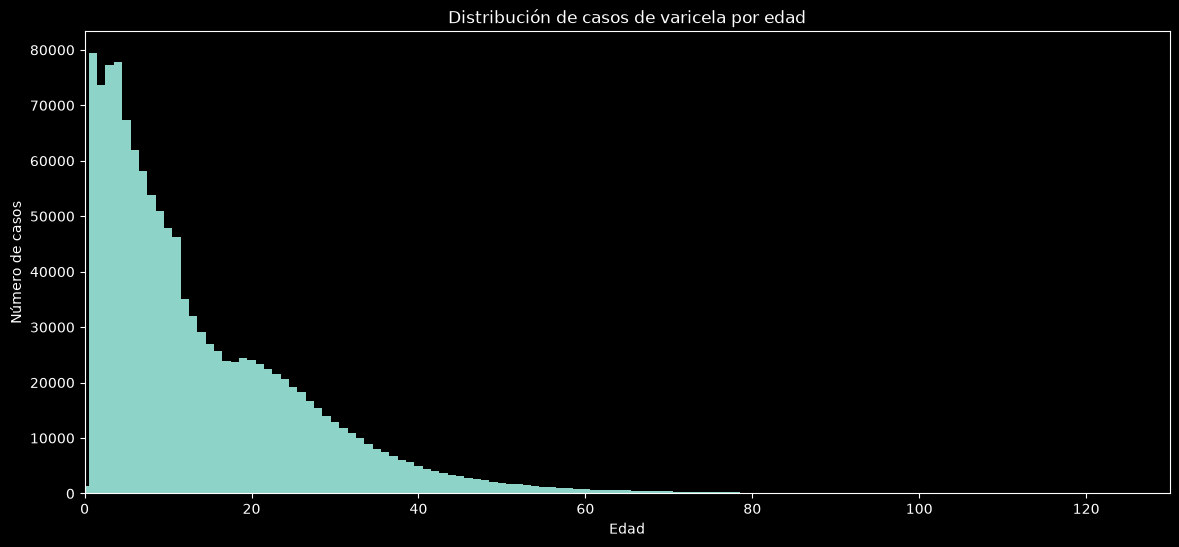

In [145]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

age_counts = (
    df10
    .filter(
        F.col("EDAD").isNotNull() &
        F.col("EDAD").cast("int").isNotNull()
    )
    .groupBy(F.col("EDAD").cast("int").alias("edad"))
    .count()
    .orderBy("edad")
    .toPandas()
)

plt.figure(figsize=(14, 6))

plt.bar(
    age_counts["edad"],
    age_counts["count"],
    width=1
)

plt.xlabel("Edad")
plt.ylabel("Número de casos")
plt.title("Distribución de casos de varicela por edad")
plt.xlim(0, age_counts["edad"].max())

plt.show()

In [143]:
print(df10.select("EDAD").distinct().show(n=200))

+----+
|EDAD|
+----+
|  31|
|  65|
|  53|
|  78|
|  34|
|  81|
|  28|
|  26|
|  27|
|  44|
|  12|
|  22|
|  47|
|   1|
|  52|
|  13|
|  16|
|   6|
|   3|
|  40|
|  20|
|  57|
|  54|
|  48|
|   5|
|  19|
|  64|
|  41|
|  15|
|  43|
|  37|
|  61|
|   9|
|  17|
|  35|
|   4|
|  55|
|  59|
|   8|
|  23|
|  39|
|  49|
|   7|
|  51|
|  69|
|  10|
|  50|
|  45|
|  38|
|  25|
|  24|
|  62|
|  29|
|  21|
|  32|
|  60|
|  75|
|  56|
|  58|
|  11|
|  33|
|  68|
|  71|
|  14|
|  42|
|   2|
|  30|
|  66|
|  46|
|  18|
|  36|
|  72|
|  77|
|  80|
|  70|
|  90|
|   0|
|  74|
|  63|
|  99|
|  76|
|  88|
|  87|
|  82|
|  73|
|  95|
|  67|
|  89|
|  96|
|  92|
|  79|
|  84|
|  85|
|  86|
|  83|
|  91|
|  93|
|  98|
|  97|
|  94|
| 116|
| 114|
| 109|
| 113|
| 130|
| 123|
| 100|
| 121|
| 103|
| 106|
| 117|
| 122|
| 101|
| 104|
| 110|
| 118|
| 105|
| 107|
| 119|
| 108|
+----+

None


In [142]:

discrepancias = (
    df10
    .withColumn(
        "inicio_semana",
        F.expr("""
            date_add(
                date_sub(
                    make_date(cast(ANO as int), 1, 4),
                    dayofweek(make_date(cast(ANO as int), 1, 4)) - 1
                ),
                (cast(SEMANA as int) - 1) * 7
            )
        """)
    )
    .withColumn("fin_semana", F.date_add("inicio_semana", 6))
    .filter(
        F.col("INI_SIN").isNotNull()
        & ~F.col("INI_SIN").between(
            F.col("inicio_semana"), F.col("fin_semana")
        )
    )
)

# discrepancias.groupBy("ANO").count().orderBy("ANO").show(30)
discrepancias.select(
    "ANO", "SEMANA", "COD_MPIO_R",
    "INI_SIN", "inicio_semana", "fin_semana"
).show(20, truncate=False)


+----+------+----------+----------+-------------+----------+
|ANO |SEMANA|COD_MPIO_R|INI_SIN   |inicio_semana|fin_semana|
+----+------+----------+----------+-------------+----------+
|2007|40    |11001     |2007-09-28|2007-09-30   |2007-10-06|
|2007|44    |11001     |2007-10-18|2007-10-28   |2007-11-03|
|2007|8     |11001     |2007-02-11|2007-02-18   |2007-02-24|
|2007|42    |11001     |2007-10-13|2007-10-14   |2007-10-20|
|2007|35    |11001     |2007-08-20|2007-08-26   |2007-09-01|
|2007|14    |11001     |2007-03-13|2007-04-01   |2007-04-07|
|2007|35    |11001     |2007-08-24|2007-08-26   |2007-09-01|
|2007|39    |11001     |2007-09-19|2007-09-23   |2007-09-29|
|2007|6     |11001     |2007-01-22|2007-02-04   |2007-02-10|
|2007|36    |11001     |2007-08-30|2007-09-02   |2007-09-08|
|2007|18    |11001     |2007-04-19|2007-04-29   |2007-05-05|
|2007|26    |11001     |2007-06-22|2007-06-24   |2007-06-30|
|2007|8     |11001     |2007-02-17|2007-02-18   |2007-02-24|
|2007|42    |11001     |